In [ ]:
import torch as t 
import numpy as np 
import matplotlib.pyplot as plt 
import os 
import pandas as pd 
import scipy 

In [12]:
class DataLoader:
    def __init__(self, directory, years, column):
        self.directory = directory
        self.years = years
        self.column = column

    def get_file_location(self, year):
        format = f"demanddata_{year}.csv"
        path = os.path.join(self.directory, format)
        if os.path.exists(path):
            print(f"found {year}")
            return path 
        raise FileNotFoundError(F"couldn't find file {year} with any of the specified formats")

    def run_on_data(self, func):
        output = []
        for year in self.years:
            loc = self.get_file_location(year)
            data = pd.read_csv(loc)
            output.append(func(data, self.column))
            print(f"{year} evaluated")
        return output 

    

In [74]:
class StatMethods:
    def get_column(self, year_data, column):
        data = year_data[column].to_numpy()
        return data
    
    def get_column_monthly_sum(self, year_data, column):
        monthly = []
        months = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"] #evil people run NESO data
        lowercasemonths = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
        for x in range(1, 13):
            if year_data["SETTLEMENT_DATE"][0][3:6] in months:
                month_data = year_data[year_data["SETTLEMENT_DATE"].str[3:6] ==months[x-1]]
                monthly.append(month_data[column].to_numpy().sum())
            elif year_data["SETTLEMENT_DATE"][0][3:6] == "Jan":
                month_data = year_data[year_data["SETTLEMENT_DATE"].str[3:6]==lowercasemonths[x-1]]
                monthly.append(month_data[column].to_numpy().sum())
            else:
                month = str(x) if len(str(x)) == 2 else "0" + str(x)
                month_data = year_data[year_data["SETTLEMENT_DATE"].str[5:7]==month]
                monthly.append(month_data[column].to_numpy().sum())
            if monthly[x-1] == 0:
                print(f"month {x} failed")
        return np.array(monthly)

            

In [ ]:
years = [x for x in range(2001, 2027)]
dataloader = DataLoader("D:/group project data/demand_data", years, "ND")
stats = StatMethods()
output = dataloader.run_on_data(stats.get_column_monthly_sum)




In [ ]:
def join_numpy_arrays(list):
    totalArray = list[0]
    for x in list[1:]:
        totalArray = np.concatenate([totalArray, x])
    return totalArray

totaloutput = join_numpy_arrays(output)



Text(0.5, 0, 'months since Jan 2001')

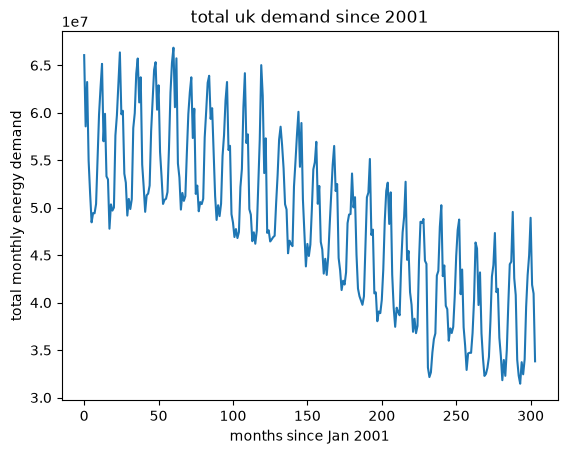

In [ ]:
totaloutput = totaloutput[:-3] #removes the final 3 months of 2026 since those aren't in the database yet. 
plt.plot([x for x in range(len(totaloutput))], totaloutput)
plt.title("total uk demand since 2001")
plt.ylabel("total monthly energy demand")
plt.xlabel("months since Jan 2001")

In [ ]:
print(len(totaloutput))

304


In [84]:
(len(totaloutput)//12)*12

300

In [ ]:
totalyearoutputs = totaloutput[:300]
yearSums = totalyearoutputs.reshape(-1, 12).sum(axis=1)


(300,)


Text(0.5, 1.0, 'annual UK grid energy demand (2001 - 2025)')

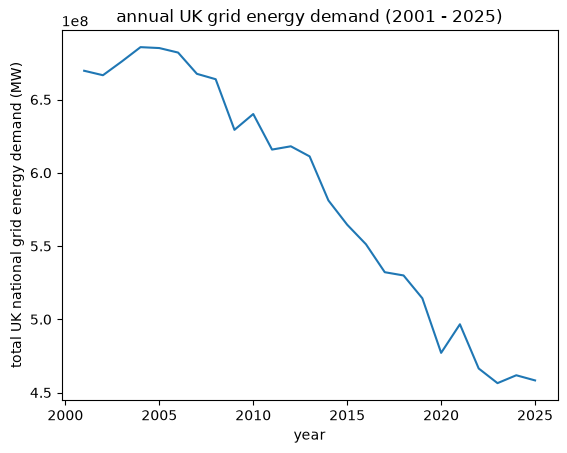

In [91]:
plt.plot([x+2001 for x in range(len(yearSums))], yearSums)
plt.xlabel("year")
plt.ylabel("total UK national grid energy demand (MW)")
plt.title("annual UK grid energy demand (2001 - 2025)")

In [ ]:
#this is 6 hours worth of work ?? ???
#we need to keep going , we could definitely get some more shit done my gng twin bruh 